In [1]:

from google.colab import files

uploaded = files.upload()


Saving task1_marketplace_delivery_sla_raw.csv to task1_marketplace_delivery_sla_raw.csv


In [2]:

import pandas as pd

df = pd.read_csv("task1_marketplace_delivery_sla_raw.csv")

print(df.head())


  order_id customer_id order_date shipped_at delivered_at updated_at  \
0    O1001         C01   29-04-26   01-05-26     03-05-26   03-05-26   
1    O1002         C02   02-05-26   03-05-26     07-05-26   07-05-26   
2    O1002         C02   02-05-26   03-05-26     07-05-26   08-05-26   
3    O1003         C03   04-05-26   05-05-26     06-05-26   06-05-26   
4    O1004         C04   05-05-26   06-05-26     01-06-26   01-06-26   

        city    courier payment_status order_status  promised_days  \
0  Bengaluru  ShipQuick           Paid    Delivered              2   
1     Mumbai  shipquick        pending    delivered              3   
2     Mumbai  ShipQuick           Paid    Delivered              3   
3      Delhi    FastBee        Pending    Delivered              2   
4       Pune  Blue Dart           Paid    Delivered              4   

   order_value is_test_order  
0         1200            No  
1          900            No  
2          900            No  
3          650        

In [3]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (10, 13)

Column Names:
['order_id', 'customer_id', 'order_date', 'shipped_at', 'delivered_at', 'updated_at', 'city', 'courier', 'payment_status', 'order_status', 'promised_days', 'order_value', 'is_test_order']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        10 non-null     object
 1   customer_id     10 non-null     object
 2   order_date      10 non-null     object
 3   shipped_at      10 non-null     object
 4   delivered_at    9 non-null      object
 5   updated_at      10 non-null     object
 6   city            10 non-null     object
 7   courier         10 non-null     object
 8   payment_status  10 non-null     object
 9   order_status    10 non-null     object
 10  promised_days   10 non-null     int64 
 11  order_value     10 non-null     int64 
 12  is_test_order   10 non-null 

In [4]:

# Convert date columns into datetime format

date_columns = [
    'order_date',
    'shipped_at',
    'delivered_at',
    'updated_at'
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format='%d-%m-%y',
        errors='coerce'
    )

# Check updated data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        10 non-null     object        
 1   customer_id     10 non-null     object        
 2   order_date      10 non-null     datetime64[ns]
 3   shipped_at      10 non-null     datetime64[ns]
 4   delivered_at    9 non-null      datetime64[ns]
 5   updated_at      10 non-null     datetime64[ns]
 6   city            10 non-null     object        
 7   courier         10 non-null     object        
 8   payment_status  10 non-null     object        
 9   order_status    10 non-null     object        
 10  promised_days   10 non-null     int64         
 11  order_value     10 non-null     int64         
 12  is_test_order   10 non-null     object        
dtypes: datetime64[ns](4), int64(2), object(7)
memory usage: 1.1+ KB


In [5]:

# Check duplicate order IDs

print("Duplicate order records:")

print(
    df[df.duplicated(
        subset='order_id',
        keep=False
    )].sort_values('order_id')
)


Duplicate order records:
  order_id customer_id order_date shipped_at delivered_at updated_at    city  \
1    O1002         C02 2026-05-02 2026-05-03   2026-05-07 2026-05-07  Mumbai   
2    O1002         C02 2026-05-02 2026-05-03   2026-05-07 2026-05-08  Mumbai   
6    O1006         C06 2026-05-10 2026-05-11   2026-05-14 2026-05-14  Mumbai   
7    O1006         C06 2026-05-10 2026-05-11   2026-05-14 2026-05-14  Mumbai   

     courier payment_status order_status  promised_days  order_value  \
1  shipquick        pending    delivered              3          900   
2  ShipQuick           Paid    Delivered              3          900   
6   Bluedart           Paid    Delivered              3         1500   
7   Bluedart           Paid    Delivered              3         1500   

  is_test_order  
1            No  
2            No  
6            No  
7            No  


In [6]:

# Sort records by latest update timestamp

df = df.sort_values(
    by='updated_at'
)

# Remove duplicate order IDs
# Keep the latest updated record

df = df.drop_duplicates(
    subset='order_id',
    keep='last'
)

# Check the result

print("Rows after removing duplicates:", len(df))

print("Unique order IDs:", df['order_id'].nunique())

print(df[['order_id', 'updated_at', 'courier']])


Rows after removing duplicates: 8
Unique order IDs: 8
  order_id updated_at    courier
0    O1001 2026-05-03  ShipQuick
3    O1003 2026-05-06    FastBee
2    O1002 2026-05-08  ShipQuick
5    O1005 2026-05-10    Fastbee
7    O1006 2026-05-14   Bluedart
8    O1007 2026-05-15  ShipQuick
9    O1008 2026-05-18    FastBee
4    O1004 2026-06-01  Blue Dart


In [7]:

# Standardize courier names

df['courier'] = df['courier'].str.strip().str.lower()

df['courier'] = df['courier'].replace({
    'shipquick': 'ShipQuick',
    'fastbee': 'FastBee',
    'bluedart': 'Blue Dart',
    'blue dart': 'Blue Dart'
})

# Check results

print(df['courier'].value_counts())


courier
ShipQuick    3
FastBee      3
Blue Dart    2
Name: count, dtype: int64


In [8]:

# Filter orders delivered in May 2026

may_orders = df[
    (df['delivered_at'].dt.month == 5) &
    (df['delivered_at'].dt.year == 2026)
]

# Display filtered orders

print("Orders delivered in May 2026:")
print(may_orders[['order_id', 'courier', 'delivered_at']])

print("\nTotal May deliveries:", len(may_orders))


Orders delivered in May 2026:
  order_id    courier delivered_at
0    O1001  ShipQuick   2026-05-03
3    O1003    FastBee   2026-05-06
2    O1002  ShipQuick   2026-05-07
7    O1006  Blue Dart   2026-05-14
8    O1007  ShipQuick   2026-05-15
9    O1008    FastBee   2026-05-18

Total May deliveries: 6


In [9]:

# Filter eligible delivered orders

eligible_orders = may_orders[
    (may_orders['order_status'].str.lower() == 'delivered') &
    (may_orders['is_test_order'].str.lower() == 'no')
].copy()

# Display eligible orders

print("Eligible orders:")
print(eligible_orders[['order_id', 'courier', 'order_status', 'is_test_order']])

print("\nTotal eligible orders:", len(eligible_orders))


Eligible orders:
  order_id    courier order_status is_test_order
0    O1001  ShipQuick    Delivered            No
3    O1003    FastBee    Delivered            No
2    O1002  ShipQuick    Delivered            No
7    O1006  Blue Dart    Delivered            No
9    O1008    FastBee    Delivered            No

Total eligible orders: 5


In [10]:

# Calculate actual delivery time in days

eligible_orders['actual_transit_days'] = (
    eligible_orders['delivered_at'] -
    eligible_orders['shipped_at']
).dt.days

# Display the result

print(
    eligible_orders[
        ['order_id', 'courier', 'shipped_at',
         'delivered_at', 'promised_days',
         'actual_transit_days']
    ]
)


  order_id    courier shipped_at delivered_at  promised_days  \
0    O1001  ShipQuick 2026-05-01   2026-05-03              2   
3    O1003    FastBee 2026-05-05   2026-05-06              2   
2    O1002  ShipQuick 2026-05-03   2026-05-07              3   
7    O1006  Blue Dart 2026-05-11   2026-05-14              3   
9    O1008    FastBee 2026-05-16   2026-05-18             -2   

   actual_transit_days  
0                    2  
3                    1  
2                    4  
7                    3  
9                    2  


In [11]:

eligible_orders['delivery_status'] = 'Late'

eligible_orders.loc[
    eligible_orders['actual_transit_days'] <= eligible_orders['promised_days'],
    'delivery_status'
] = 'On Time'

print(eligible_orders[
    ['order_id', 'courier', 'actual_transit_days',
     'promised_days', 'delivery_status']
])

  order_id    courier  actual_transit_days  promised_days delivery_status
0    O1001  ShipQuick                    2              2         On Time
3    O1003    FastBee                    1              2         On Time
2    O1002  ShipQuick                    4              3            Late
7    O1006  Blue Dart                    3              3         On Time
9    O1008    FastBee                    2             -2            Late


In [12]:
summary = eligible_orders.groupby('courier').agg(
    eligible_orders=('order_id', 'count'),
    on_time_orders=('delivery_status', lambda x: (x == 'On Time').sum())
).reset_index()

summary['on_time_rate'] = (
    summary['on_time_orders'] / summary['eligible_orders']
)

print(summary)

     courier  eligible_orders  on_time_orders  on_time_rate
0  Blue Dart                1               1           1.0
1    FastBee                2               1           0.5
2  ShipQuick                2               1           0.5


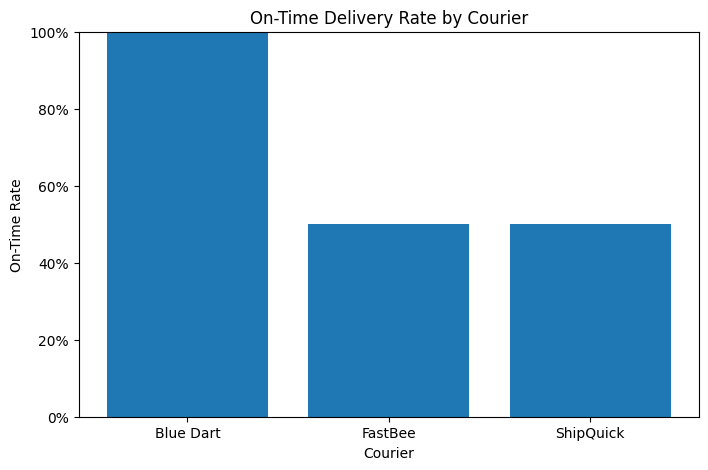

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(summary['courier'], summary['on_time_rate'])

plt.title('On-Time Delivery Rate by Courier')
plt.xlabel('Courier')
plt.ylabel('On-Time Rate')
plt.ylim(0, 1)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0%}')
)

plt.show()

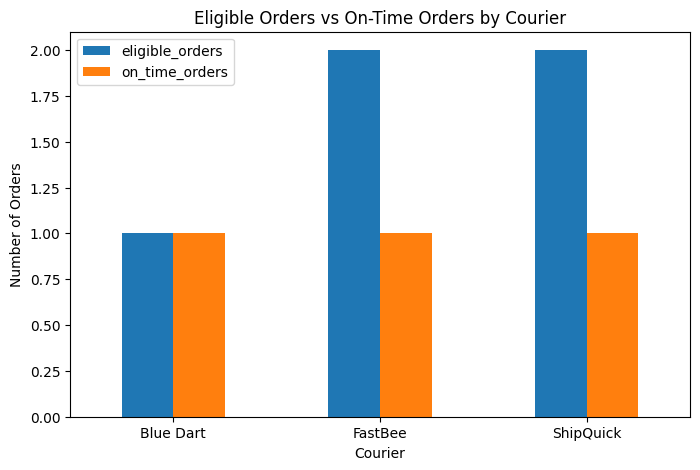

In [14]:
summary.plot(
    x='courier',
    y=['eligible_orders', 'on_time_orders'],
    kind='bar',
    figsize=(8, 5)
)

plt.title('Eligible Orders vs On-Time Orders by Courier')
plt.xlabel('Courier')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.show()